# 01 Topic Modeling

Data tanpa label, tujuannya menemukan tema. Contoh: komentar YouTube tentang program MBG.

**Daftar isi**

1. Kartu Masalah
2. Kapan Pakai Notebook Ini
3. Config
4. EDA
5. Preprocessing
6. Validasi
7. Baseline
8. Model Utama
9. Post-processing
10. Post-analysis
11. Keluaran

## 1. Kartu Masalah

| Bagian | Isi |
|---|---|
| **Task** | Menemukan topik tanpa label |
| **Unit prediksi** | Satu komentar mendapat satu topik |
| **Metrik** | NPMI, diversity, dan stabilitas antar seed (ARI) |
| **Masalah terbesar** | Komentar pendek dan kotor: median 17 kata, maksimum 1.446 kata, 17,8% berisi tag HTML. Tidak ada label untuk menilai hasil. |
| **Data contoh** | 5.000 komentar YouTube tentang MBG |

## 2. Kapan Pakai Notebook Ini

**Pakai kalau** soal meminta menemukan topik atau tema dari teks tanpa label. Metriknya biasanya
coherence (NPMI), diversity, silhouette, atau penilaian kualitas topik saat presentasi.

**Kalau ada label tersembunyi** dan penilaiannya NMI atau ARI, pakai folder `03`.

**Yang perlu diganti kalau datanya beda:**
- `load_data` dan `TEXT_COL` di bagian 3 dan 4.
- `DOMAIN_STOPWORDS`, isi dengan kata yang muncul di hampir semua dokumen.
- `K_GRID`, sesuaikan dengan jumlah topik yang masuk akal atau yang diminta soal.

## 3. Config

**Import dan lingkungan.** Mode offline dinyalakan di sini, dan progress bar serta warning
dimatikan supaya output tetap bersih.

In [1]:
import importlib.util
import json
import os
import random
import subprocess
import sys
import time
import warnings
from contextlib import contextmanager
from pathlib import Path

os.environ.update(
    CUDA_VISIBLE_DEVICES="0",
    HF_HUB_OFFLINE="1",
    TRANSFORMERS_OFFLINE="1",
    TOKENIZERS_PARALLELISM="false",
    TQDM_DISABLE="1",
    PYTHONWARNINGS="ignore",
    HF_HUB_DISABLE_PROGRESS_BARS="1",
)
warnings.filterwarnings("ignore")
sys.modules["tensorflow"] = None  # tidak dipakai; mencegah log TensorFlow saat umap diimpor

import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402
import torch  # noqa: E402
from transformers.utils import logging as hf_logging  # noqa: E402

hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
pd.set_option("display.max_colwidth", 90, "display.max_rows", 30, "display.width", 140)
plt.rcParams.update(
    {
        "figure.figsize": (8, 3.5),
        "figure.dpi": 90,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)
print(f"device={DEVICE} | torch={torch.__version__}")

device=cuda | torch=2.11.0+cu130


**Lokasi file.** `find_pack` mencari paket offline, dan `find_file` mencari file data di Kaggle
atau folder lokal. Di mesin lokal, set `PACK_DIR` dan `DATA_ROOT` lewat environment variable.

In [2]:
INPUT_ROOTS = [Path(p) for p in (os.environ.get("DATA_ROOT"), "/kaggle/input", ".") if p]


def find_pack() -> Path:
    """Cari folder paket offline lewat file pack_manifest.json."""
    if os.environ.get("PACK_DIR"):
        return Path(os.environ["PACK_DIR"])
    for root in INPUT_ROOTS:
        for manifest in root.glob("**/pack_manifest.json"):
            return manifest.parent
    raise FileNotFoundError("Paket offline tidak ketemu. Set environment variable PACK_DIR.")


def find_file(name: str) -> Path:
    """Cari file data berdasarkan nama di semua folder input."""
    for root in INPUT_ROOTS:
        for path in root.glob(f"**/{name}"):
            return path
    raise FileNotFoundError(f"File {name} tidak ketemu di {INPUT_ROOTS}")


def install_offline(*modules: str) -> None:
    """Pasang library dari wheel paket offline, hanya bila belum terpasang."""
    missing = [m for m in modules if importlib.util.find_spec(m.replace("-", "_")) is None]
    if missing:
        subprocess.run(
            [
                sys.executable,
                "-m",
                "pip",
                "install",
                "-q",
                "--no-index",
                "--find-links",
                str(PACK_DIR / "wheels"),
                "--root-user-action=ignore",
                *missing,
            ],
            check=True,
        )


PACK_DIR = find_pack()
MODEL_DIR = PACK_DIR / "models"
EXTRA_DATA_DIR = PACK_DIR / "data"
RESULT_DIR = Path("hasil")
RESULT_DIR.mkdir(exist_ok=True)
print(f"paket offline: {PACK_DIR}")

paket offline: /kaggle/input/notebooks/ivanwllm/gemastik-nlp-00-setup-offline


**Pencatat waktu dan ringkasan.** `stage` mencatat durasi tiap tahap, dan `run_summary` mencetak
ringkasan akhir yang dibaca skrip audit.

In [3]:
RUN_START = time.time()
STAGE_SECONDS: dict[str, float] = {}


@contextmanager
def stage(name: str):
    """Catat durasi satu tahap."""
    start = time.time()
    yield
    STAGE_SECONDS[name] = round(time.time() - start, 1)
    print(f"[waktu] {name}: {STAGE_SECONDS[name]:.0f} detik")


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def run_summary(task: str, n_rows: int, metrics: dict, needs_gpu: bool = True) -> None:
    """Simpan dan cetak ringkasan run."""
    total = int(time.time() - RUN_START)
    used_gpu = torch.cuda.is_available() and torch.cuda.max_memory_allocated() > 0
    summary = {
        "task": task,
        "mode": MODE,
        "use_pretrained": USE_PRETRAINED,
        "n_rows": n_rows,
        "total_detik": total,
        "gpu": used_gpu,
        "tahap_detik": STAGE_SECONDS,
        "metrik": metrics,
    }
    (RESULT_DIR / "ringkasan.json").write_text(json.dumps(summary, indent=1))
    note = "" if needs_gpu else " gpu_tidak_wajib"
    print(
        f"RINGKASAN_RUN task={task} mode={MODE} n_rows={n_rows} total_detik={total} "
        f"gpu={used_gpu}{note}"
    )
    print(json.dumps(metrics, indent=1))

**Pengaturan utama.** Semua yang perlu diubah ada di sel ini.

In [4]:
MODE = "penuh"  # "cepat" (<30 menit) atau "penuh" (<2 jam)
USE_PRETRAINED = True  # False: embedding memakai TF-IDF + SVD, tanpa file model dari luar
SEED = 42
N_ROWS = 5000
TEXT_COL = "Comment"
DOMAIN_STOPWORDS = {"mbg", "makan", "bergizi", "gratis", "program", "prof", "gema"}
TOP_WORDS = 10

SETTINGS = {
    "cepat": {"k_grid": [6, 10, 15], "stability_seeds": [1, 2]},
    "penuh": {"k_grid": [5, 6, 8, 10, 12, 15, 20, 25], "stability_seeds": [1, 2, 3, 4, 5]},
}[MODE]

seed_everything(SEED)
print(SETTINGS)

{'k_grid': [5, 6, 8, 10, 12, 15, 20, 25], 'stability_seeds': [1, 2, 3, 4, 5]}


**Util teks.** `clean_text` hanya membuang gangguan teknis (URL, mention, spasi) dan
mempertahankan emoji serta tanda seru karena keduanya membawa sinyal. `normalize_slang` memakai
kamus alay. `near_duplicate_groups` menemukan komentar kembar supaya tidak bocor antar fold.

In [5]:
import re  # noqa: E402

from sklearn.feature_extraction.text import TfidfVectorizer  # noqa: E402
from sklearn.linear_model import LogisticRegression  # noqa: E402
from sklearn.metrics import roc_auc_score  # noqa: E402
from sklearn.model_selection import cross_val_predict  # noqa: E402
from sklearn.neighbors import NearestNeighbors  # noqa: E402

URL_RE = re.compile(r"https?://\S+|www\.\S+")
MENTION_RE = re.compile(r"@\w+")
SPACE_RE = re.compile(r"\s+")


def clean_text(text: str) -> str:
    """Bersihkan URL, mention, dan spasi berlebih. Huruf kecil, emoji tetap."""
    text = URL_RE.sub(" ", str(text))
    text = MENTION_RE.sub(" ", text)
    return SPACE_RE.sub(" ", text).strip().lower()


def load_slang_dict() -> dict[str, str]:
    """Muat kamus kata informal ke kata baku."""
    path = next((EXTRA_DATA_DIR / "kamus_alay").glob("**/colloquial-indonesian-lexicon.csv"))
    lexicon = pd.read_csv(path)
    return dict(zip(lexicon["slang"].astype(str), lexicon["formal"].astype(str)))


def normalize_slang(text: str, slang: dict[str, str]) -> str:
    """Ganti kata informal dengan kata baku, per kata."""
    return " ".join(slang.get(word, word) for word in text.split())


def near_duplicate_groups(texts: list[str], threshold: float = 0.9) -> np.ndarray:
    """Beri id grup yang sama pada teks yang kemiripan char TF-IDF-nya di atas threshold."""
    vectors = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=1).fit_transform(texts)
    neighbors = NearestNeighbors(n_neighbors=min(6, len(texts)), metric="cosine").fit(vectors)
    distance, index = neighbors.kneighbors(vectors)
    parent = list(range(len(texts)))

    def root(i: int) -> int:
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i

    for i, (row_dist, row_idx) in enumerate(zip(distance, index)):
        for dist, j in zip(row_dist, row_idx):
            if dist <= 1 - threshold:
                parent[root(i)] = root(int(j))
    return np.array([root(i) for i in range(len(texts))])


def adversarial_auc(texts_a: list[str], texts_b: list[str]) -> float:
    """AUC model yang membedakan dua kumpulan teks. Dekat 0,5 berarti tidak ada shift."""
    texts = list(texts_a) + list(texts_b)
    target = np.array([0] * len(texts_a) + [1] * len(texts_b))
    vectors = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True).fit_transform(texts)
    model = LogisticRegression(max_iter=1000, class_weight="balanced")
    scores = cross_val_predict(model, vectors, target, cv=3, method="predict_proba")[:, 1]
    return float(roc_auc_score(target, scores))


def text_profile(texts: pd.Series) -> pd.Series:
    """Ringkasan kualitas teks untuk EDA."""
    words = texts.astype(str).str.split().str.len()
    return pd.Series(
        {
            "baris": len(texts),
            "kosong": int((words == 0).sum()),
            "duplikat_persis_%": round(100 * texts.duplicated().mean(), 1),
            "kata_median": float(words.median()),
            "kata_p95": float(words.quantile(0.95)),
            "kata_maks": int(words.max()),
            "ada_url_%": round(100 * texts.astype(str).str.contains(r"https?://").mean(), 1),
            "ada_emoji_%": round(
                100 * texts.astype(str).str.contains(r"[\U0001F300-\U0001FAFF]").mean(), 1
            ),
        }
    )

**Stopword.** Daftar ini hanya dipakai untuk merangkum kata kunci topik, bukan untuk input model
embedding. Tambahkan kata yang terlalu umum di kasus lu, misalnya `mbg` dan `makan`.

In [6]:
STOPWORDS = set(
    """
    ada adalah agar akan aku anda apa apakah atas atau bagaimana bagi bahkan bahwa banyak baru
    begitu belum benar berapa bersama bisa buat bukan cuma dalam dan dapat dari dengan di dia
    dong dulu gak ga gitu gue gua hanya harus hal ini itu iya jadi jangan juga jika kalau kalo
    kami kamu kan karena kata ke kita kok lagi lah lain lalu lebih lu lo masih mau maka mana
    memang mereka meski mungkin nah nanti ni nya oleh pada pak para pun punya saat saja sama
    sampai saya sebagai sebagainya sedang sudah sudah sih seperti siapa supaya tak tapi telah
    tentang terus tetapi tidak tuh udah untuk ya yaitu yang yg dgn dg krn utk tdk jg aja kalo
    aja nih deh kak bang bu ibu bapak sekarang semua setiap sangat tanpa ketika orang enggak
    quot amp mas mbak sih dah tau kayak kaya sampe gimana emang kenapa
    """.split()
)

**Embedding teks.** Kalau pretrained boleh dipakai, teks diubah dengan multilingual-e5. Kalau
tidak boleh, `USE_PRETRAINED=False` memakai TF-IDF + SVD sebagai gantinya.

In [7]:
from sklearn.decomposition import TruncatedSVD  # noqa: E402
from sklearn.feature_extraction.text import TfidfVectorizer as _Tfidf  # noqa: E402
from sklearn.preprocessing import normalize as _l2  # noqa: E402
from transformers import AutoModel, AutoTokenizer  # noqa: E402


def tfidf_svd_embed(texts: list[str], dim: int = 256) -> np.ndarray:
    """Embedding tanpa pretrained: TF-IDF kata + SVD."""
    matrix = _Tfidf(ngram_range=(1, 2), min_df=2, sublinear_tf=True).fit_transform(texts)
    dim = min(dim, matrix.shape[1] - 1, matrix.shape[0] - 1)
    return _l2(TruncatedSVD(dim, random_state=SEED).fit_transform(matrix))


@torch.inference_mode()
def e5_embed(texts: list[str], prefix: str = "query: ", batch_size: int = 64) -> np.ndarray:
    """Mean pooling multilingual-e5, hasil dinormalisasi L2."""
    tokenizer = AutoTokenizer.from_pretrained(MODEL_DIR / "e5")
    model = AutoModel.from_pretrained(MODEL_DIR / "e5").to(DEVICE).eval().half()
    order = np.argsort([len(t) for t in texts])
    chunks = []
    for start in range(0, len(texts), batch_size):
        batch = [prefix + texts[i] for i in order[start : start + batch_size]]
        tokens = tokenizer(
            batch, padding=True, truncation=True, max_length=128, return_tensors="pt"
        ).to(DEVICE)
        hidden = model(**tokens).last_hidden_state
        mask = tokens["attention_mask"].unsqueeze(-1).to(hidden.dtype)
        pooled = (hidden * mask).sum(1) / mask.sum(1)
        chunks.append(torch.nn.functional.normalize(pooled, dim=1).float().cpu().numpy())
    del model
    torch.cuda.empty_cache()
    vectors = np.empty((len(texts), chunks[0].shape[1]), dtype=np.float32)
    vectors[order] = np.vstack(chunks)
    return vectors


def embed_texts(texts: list[str]) -> np.ndarray:
    """Pilih embedding sesuai USE_PRETRAINED."""
    return e5_embed(texts) if USE_PRETRAINED else tfidf_svd_embed(texts)

## 4. EDA

Muat data dan lihat kualitas teksnya.

In [8]:
def load_data() -> pd.DataFrame:
    frame = pd.read_csv(find_file("comment_data.csv"))
    return frame.dropna(subset=[TEXT_COL]).head(N_ROWS).reset_index(drop=True)


data = load_data()
print(f"baris: {len(data)}")
text_profile(data[TEXT_COL])

baris: 5000


baris                5000.0
kosong                  0.0
duplikat_persis_%       0.8
kata_median            17.0
kata_p95               87.0
kata_maks            1446.0
ada_url_%               2.0
ada_emoji_%            13.4
dtype: float64

Kata terbanyak sebelum dibersihkan, dan apakah ada komentar yang sama persis berulang.

Komentar paling sering berulang:
Comment
Kok pas banget kebongkar korupsi di BGN sama statement Teddy yg bilang kunjungan    6
Anak pelaut Bugis Makassar mengelilingi samudera Atlantik mencari cinta sejati d    5
Mantap                                                                              5
Bubarkan mbg                                                                        3
Good                                                                                3

Ada tag HTML: 17.8 %


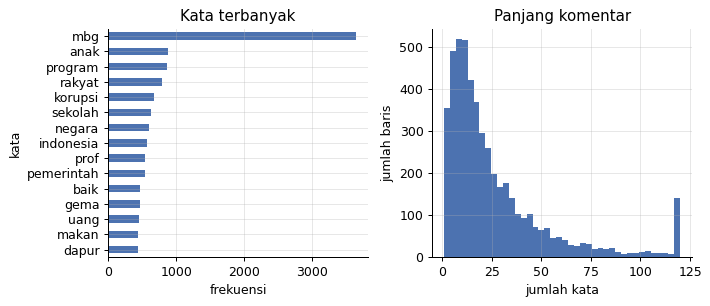

In [9]:
raw_words = data[TEXT_COL].astype(str).str.lower().str.findall(r"[a-z]{3,}").explode()
top_raw = raw_words[~raw_words.isin(STOPWORDS)].value_counts().head(15)
top_repeated = data[TEXT_COL].astype(str).str[:80].value_counts().head(5)
print("Komentar paling sering berulang:")
print(top_repeated.to_string())
print(
    "\nAda tag HTML:",
    round(100 * data[TEXT_COL].astype(str).str.contains("<br>|<a ").mean(), 1),
    "%",
)

fig, axes = plt.subplots(1, 2)
top_raw.sort_values().plot.barh(ax=axes[0], color="#4C72B0")
axes[0].set(title="Kata terbanyak", xlabel="frekuensi", ylabel="kata")
data[TEXT_COL].astype(str).str.split().str.len().clip(upper=120).plot.hist(
    bins=40, ax=axes[1], color="#4C72B0"
)
axes[1].set(title="Panjang komentar", xlabel="jumlah kata", ylabel="jumlah baris")
plt.tight_layout()
plt.show()

**Temuan dan keputusan**

| Temuan | Keputusan |
|---|---|
| 17,8% komentar berisi tag HTML | HTML dibuang, supaya tidak jadi kata kunci topik |
| Ada komentar yang sama persis dan sangat pendek, misalnya `Mantap` | Duplikat disatukan dan komentar pendek dibuang, sisa 4.456 baris |
| Median 17 kata, jadi jarang muncul kata yang sama | Pakai dua versi teks: `clean` untuk embedding, `words` untuk kata kunci |
| HDBSCAN meninggalkan 35,2% outlier | Outlier ditempelkan ke cluster terdekat, dan NMF tetap dibandingkan |

## 5. Preprocessing

Dua versi teks: `clean` untuk embedding, dan `words` tanpa stopword untuk kata kunci topik. HTML dan
komentar yang terlalu pendek dibuang, sedangkan duplikat dijadikan satu supaya tidak membentuk
topik semu.

In [10]:
import html  # noqa: E402

HTML_RE = re.compile(r"<[^>]+>")
slang = load_slang_dict()
all_stopwords = STOPWORDS | DOMAIN_STOPWORDS

data["clean"] = (
    data[TEXT_COL].astype(str).map(lambda t: clean_text(HTML_RE.sub(" ", html.unescape(t))))
)
data["formal"] = data["clean"].map(lambda t: normalize_slang(t, slang))
data["words"] = data["formal"].map(
    lambda t: " ".join(w for w in re.findall(r"[a-z]{3,}", t) if w not in all_stopwords)
)
before = len(data)
data = (
    data[data["words"].str.split().str.len() >= 3].drop_duplicates("clean").reset_index(drop=True)
)
print(f"baris sebelum={before}, sesudah={len(data)}")
data[["clean", "words"]].head(3)

baris sebelum=5000, sesudah=4456


,clean,words
0,bagaimana pendapat kamu tentang mbg? tulis pandangan kamu di kolom komentar! mau dapet...,pendapat tulis pandangan kolom komentar rekomendasi trading master gabung club sini
1,"siapa bilang 15 atau 13 teori doang, 8000 iya",bilang teori doang
2,"maksut gw apa yg d omongin, tp klu dah terlanjur gini gmn penyelesainnya .. tutup aja ...",maksut omongin terlanjur begini penyelesainnya tutup bagus


## 6. Validasi

Tidak ada label, jadi yang dinilai adalah kualitas topik. Metrik ditulis sendiri dan diuji dulu:
- **NPMI**: kata dalam satu topik sering muncul bersama atau tidak. Rentang -1 sampai 1.
- **Diversity**: bagian kata kunci yang unik antar topik.
- **Silhouette**: pemisahan cluster, selalu dihitung di ruang embedding yang sama supaya adil.

Satu angka saja tidak cukup, karena coherence bisa bagus padahal silhouette mendekati nol.

In [11]:
from scipy.sparse import csr_matrix  # noqa: E402
from sklearn.feature_extraction.text import CountVectorizer  # noqa: E402
from sklearn.metrics import adjusted_rand_score, silhouette_score  # noqa: E402

vectorizer = CountVectorizer(min_df=5, max_df=0.2, token_pattern=r"\b[a-z]{3,}\b")
counts = vectorizer.fit_transform(data["words"])
vocab = np.array(vectorizer.get_feature_names_out())
presence = (counts > 0).astype(np.int32)
print(f"kosakata: {len(vocab)} kata")


def npmi_coherence(topics: list[list[int]], doc_word) -> float:
    """Rata-rata NPMI pasangan kata kunci per topik, dihitung dari kemunculan dalam dokumen."""
    n_docs = doc_word.shape[0]
    together = (doc_word.T @ doc_word).tocsr()
    doc_freq = np.asarray(doc_word.sum(0)).ravel()
    scores = []
    for words in topics:
        for a, word_a in enumerate(words):
            for word_b in words[a + 1 :]:
                joint = together[word_a, word_b] / n_docs
                if joint == 0:
                    scores.append(-1.0)
                    continue
                pmi = np.log(joint / (doc_freq[word_a] / n_docs * doc_freq[word_b] / n_docs))
                scores.append(pmi / -np.log(joint))
    return float(np.mean(scores))


def topic_diversity(topics: list[list[int]]) -> float:
    flat = [w for words in topics for w in words]
    return len(set(flat)) / len(flat)


_toy = np.array([[1, 1, 0], [1, 1, 0], [0, 0, 1], [0, 0, 1]], dtype=np.int32)
assert abs(npmi_coherence([[0, 1]], csr_matrix(_toy)) - 1.0) < 1e-9
assert topic_diversity([[0, 1], [1, 2]]) == 0.75

kosakata: 2445 kata


**Embedding** dihitung sekali di sini, karena dipakai oleh semua model untuk menghitung silhouette.

In [12]:
with stage("embedding"):
    embeddings = embed_texts(data["clean"].tolist())
print("embedding:", embeddings.shape)

[waktu] embedding: 33 detik
embedding: (4456, 768)


**Kata kunci c-TF-IDF** dipakai untuk semua model supaya perbandingannya adil. Kata yang sering di
satu topik tapi jarang di topik lain mendapat skor tinggi.

In [13]:
def ctfidf_topics(labels: np.ndarray) -> tuple[list[int], list[list[int]]]:
    """Kembalikan id topik dan kata kuncinya. Label -1 (outlier) dilewati."""
    topic_ids = [t for t in np.unique(labels) if t != -1]
    per_topic = np.vstack([np.asarray(counts[labels == t].sum(0)).ravel() for t in topic_ids])
    term_freq = per_topic / np.maximum(per_topic.sum(1, keepdims=True), 1)
    avg_words = per_topic.sum() / len(topic_ids)
    idf = np.log(1 + avg_words / np.maximum(per_topic.sum(0), 1))
    scores = term_freq * idf
    return topic_ids, [list(np.argsort(-row)[:TOP_WORDS]) for row in scores]


def evaluate(name: str, k: int, labels: np.ndarray) -> dict:
    """Hitung semua metrik untuk satu hasil topik."""
    _, topics = ctfidf_topics(labels)
    silhouette = silhouette_score(
        embeddings, labels, metric="cosine", sample_size=min(3000, len(labels)), random_state=SEED
    )
    return {
        "model": name,
        "k": k,
        "npmi": round(npmi_coherence(topics, presence), 4),
        "diversity": round(topic_diversity(topics), 3),
        "silhouette": round(float(silhouette), 4),
    }

## 7. Baseline

Dua pembanding klasik: NMF pada TF-IDF, dan LDA pada hitungan kata. Keduanya tidak butuh model dari
luar, jadi tetap bisa dipakai kalau pretrained dilarang.

In [14]:
from sklearn.decomposition import NMF, LatentDirichletAllocation  # noqa: E402
from sklearn.feature_extraction.text import TfidfTransformer  # noqa: E402

tfidf_counts = TfidfTransformer(sublinear_tf=True).fit_transform(counts)


def nmf_labels(k: int, seed: int) -> np.ndarray:
    model = NMF(k, random_state=seed, init="nndsvda", max_iter=400)
    return model.fit_transform(tfidf_counts).argmax(1)


def lda_labels(k: int, seed: int) -> np.ndarray:
    model = LatentDirichletAllocation(k, random_state=seed, learning_method="online")
    return model.fit_transform(counts).argmax(1)


results: list[dict] = []
runs: dict[tuple[str, int], np.ndarray] = {}
with stage("baseline"):
    for k in SETTINGS["k_grid"]:
        for name, fit_fn in (("nmf", nmf_labels), ("lda", lda_labels)):
            runs[(name, k)] = fit_fn(k, SEED)
            results.append(evaluate(name, k, runs[(name, k)]))
pd.DataFrame(results).sort_values("npmi", ascending=False).head(6)

[waktu] baseline: 56 detik


,model,k,npmi,diversity,silhouette
5,lda,8,0.1769,0.738,-0.0136
4,nmf,8,0.1730,0.838,-0.0079
0,nmf,5,0.1727,0.860,0.0017
6,nmf,10,0.1653,0.800,-0.0057
8,nmf,12,0.1546,0.825,-0.0054
10,nmf,15,0.1527,0.807,-0.0113


## 8. Model Utama

**Embedding + UMAP + clustering + c-TF-IDF.** Embedding menangkap makna walau katanya berbeda,
UMAP mengecilkan dimensi, lalu clustering membentuk topik. KMeans memaksa semua dokumen masuk topik,
sedangkan HDBSCAN menentukan jumlah topik sendiri dan menandai sisanya sebagai outlier.

In [15]:
import umap  # noqa: E402
from sklearn.cluster import HDBSCAN, KMeans  # noqa: E402


def reduce_embeddings(seed: int) -> np.ndarray:
    reducer = umap.UMAP(
        n_neighbors=15, n_components=5, min_dist=0.0, metric="cosine", random_state=seed
    )
    return reducer.fit_transform(embeddings)


with stage("umap"):
    reduced = reduce_embeddings(SEED)
print("umap:", reduced.shape)

[waktu] umap: 26 detik
umap: (4456, 5)


Coba KMeans di semua nilai k, dan HDBSCAN yang outlier-nya ditempelkan ke topik terdekat.

In [16]:
def assign_outliers(labels: np.ndarray) -> np.ndarray:
    """Tempelkan dokumen outlier ke centroid topik terdekat."""
    labels = labels.copy()
    topic_ids = [t for t in np.unique(labels) if t != -1]
    centroids = np.vstack([embeddings[labels == t].mean(0) for t in topic_ids])
    outliers = np.where(labels == -1)[0]
    if len(outliers):
        nearest = (embeddings[outliers] @ centroids.T).argmax(1)
        labels[outliers] = np.array(topic_ids)[nearest]
    return labels


with stage("clustering"):
    for k in SETTINGS["k_grid"]:
        runs[("embed_kmeans", k)] = KMeans(k, random_state=SEED, n_init=10).fit_predict(reduced)
        results.append(evaluate("embed_kmeans", k, runs[("embed_kmeans", k)]))
    min_cluster = max(15, len(data) // 150)
    raw_hdbscan = HDBSCAN(min_cluster_size=min_cluster, min_samples=5).fit_predict(reduced)
    outlier_share = float((raw_hdbscan == -1).mean())
    hdbscan_labels = assign_outliers(raw_hdbscan)
    hdbscan_k = len(np.unique(hdbscan_labels))
    runs[("embed_hdbscan", hdbscan_k)] = hdbscan_labels
    results.append(evaluate("embed_hdbscan", hdbscan_k, hdbscan_labels))
print(f"outlier HDBSCAN sebelum ditempelkan: {outlier_share:.1%}")
result_table = pd.DataFrame(results)
result_table.to_csv(RESULT_DIR / "perbandingan.csv", index=False)
result_table.sort_values("npmi", ascending=False).head(10)

[waktu] clustering: 3 detik
outlier HDBSCAN sebelum ditempelkan: 35.2%


,model,k,npmi,diversity,silhouette
5,lda,8,0.1769,0.738,-0.0136
4,nmf,8,0.1730,0.838,-0.0079
0,nmf,5,0.1727,0.860,0.0017
6,nmf,10,0.1653,0.800,-0.0057
8,nmf,12,0.1546,0.825,-0.0054
10,nmf,15,0.1527,0.807,-0.0113
2,nmf,6,0.1526,0.883,-0.0053
3,lda,6,0.1498,0.800,-0.0059
1,lda,5,0.1391,0.800,0.0008
12,nmf,20,0.1380,0.810,-0.0146


## 9. Post-processing

Pilih model dari skor gabungan peringkat NPMI, diversity, dan silhouette. Peringkat dipakai karena
skala ketiganya berbeda. Topik yang terlalu kecil lalu digabung ke topik terdekat.

In [17]:
result_table["skor"] = result_table[["npmi", "diversity", "silhouette"]].rank(pct=True).mean(axis=1)
best = result_table.sort_values("skor", ascending=False).iloc[0]
best_key = (best["model"], int(best["k"]))
print("dipilih:", best_key)


def merge_small_topics(labels: np.ndarray, min_share: float = 0.01) -> np.ndarray:
    """Gabungkan topik di bawah min_share ke centroid topik besar terdekat."""
    labels = labels.copy()
    sizes = pd.Series(labels).value_counts(normalize=True)
    big = sizes[sizes >= min_share].index.to_numpy()
    centroids = np.vstack([embeddings[labels == t].mean(0) for t in big])
    for topic in sizes[sizes < min_share].index:
        members = labels == topic
        labels[members] = big[(embeddings[members].mean(0) @ centroids.T).argmax()]
    return labels


final_labels = merge_small_topics(runs[best_key])
topic_ids, final_topics = ctfidf_topics(final_labels)
final_scores = evaluate("final", len(topic_ids), final_labels)
final_scores

dipilih: ('nmf', 5)


{'model': 'final',
 'k': 5,
 'npmi': 0.1727,
 'diversity': 0.86,
 'silhouette': 0.0017}

## 10. Post-analysis

**Isi tiap topik:** kata kunci, ukuran, dan komentar yang paling mewakili.

In [18]:
rows = []
for topic, words in zip(topic_ids, final_topics):
    members = np.where(final_labels == topic)[0]
    centroid = embeddings[members].mean(0)
    closest = members[np.argmax(embeddings[members] @ centroid)]
    rows.append(
        {
            "topik": int(topic),
            "jumlah": len(members),
            "kata_kunci": ", ".join(vocab[words][:7]),
            "contoh": data["clean"].iloc[closest][:90],
        }
    )
topic_table = pd.DataFrame(rows).sort_values("jumlah", ascending=False)
topic_table.to_csv(RESULT_DIR / "topik.csv", index=False)
topic_table

,topik,jumlah,kata_kunci,contoh
2,2,1293,"harga, dapur, sppg, petani, kerja, lapangan, bahan","mbg itu bagus ,hanya tata kelolanya yg tidak bagus .,saya berharap dapur mbg seperti d..."
0,0,1291,"rakyat, negara, indonesia, presiden, prabowo, baik, pemerintah","mbg dari segi manapun tidak ada bagusnya,duit segede itu kalau buat pendidikan dan kes..."
4,4,734,"korupsi, koruptor, hukum, mati, bagus, pejabat, negara",program mbg bagus. tapi stop lebih bagus. pemborosan sumber korupsi. bisa hancurkan ne...
1,1,709,"anak, sekolah, makanan, tua, miskin, mampu, gizi","menurutku mbg itu banyak manfaat nya bagi masyarakat ,anak2 suka kok mbg,untuk para or..."
3,3,429,"kasih, data, terima, mahasiswa, mantap, demo, solusi",suka sekali penjelasan prof gema..jelas lugas dgn data yg akurat tdk hanya omdo..bisa ...


**Sebaran ukuran topik** untuk melihat apakah ada satu topik yang mendominasi.

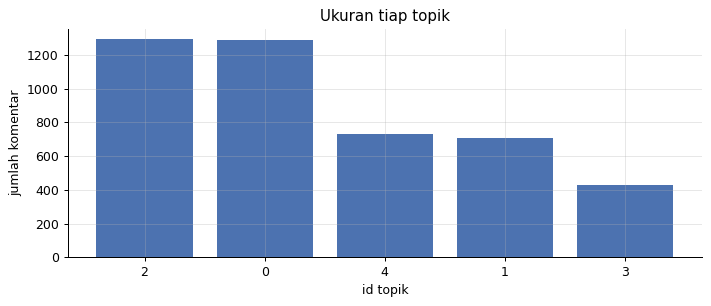

In [19]:
fig, ax = plt.subplots()
ax.bar(topic_table["topik"].astype(str), topic_table["jumlah"], color="#4C72B0")
ax.set(title="Ukuran tiap topik", xlabel="id topik", ylabel="jumlah komentar")
plt.tight_layout()
plt.show()

**Stabilitas.** Metode terpilih dijalankan ulang dengan seed lain, termasuk seed UMAP. ARI mendekati
1 berarti stabil, mendekati 0 berarti hasilnya banyak dipengaruhi kebetulan.

In [20]:
def refit_labels(seed: int) -> np.ndarray:
    name, k = best_key
    if name == "nmf":
        return nmf_labels(k, seed)
    if name == "lda":
        return lda_labels(k, seed)
    new_reduced = reduce_embeddings(seed)
    if name == "embed_kmeans":
        return KMeans(k, random_state=seed, n_init=10).fit_predict(new_reduced)
    return assign_outliers(
        HDBSCAN(min_cluster_size=min_cluster, min_samples=5).fit_predict(new_reduced)
    )


with stage("stabilitas"):
    stability = [
        adjusted_rand_score(runs[best_key], refit_labels(s)) for s in SETTINGS["stability_seeds"]
    ]
stability_mean = float(np.mean(stability))
print(f"ARI antar seed: {np.round(stability, 3)} | rata-rata {stability_mean:.3f}")

[waktu] stabilitas: 2 detik
ARI antar seed: [0.984 0.988 0.988 0.975 0.985] | rata-rata 0.984


## 11. Keluaran

Label topik per dokumen dan ringkasan run.

In [21]:
submission = pd.DataFrame({"id": data.index, "topic": final_labels})
submission.to_csv(RESULT_DIR / "submission.csv", index=False)
run_summary(
    "topic_modeling",
    len(data),
    {
        "final": final_scores,
        "dipilih": f"{best_key[0]}_{best_key[1]}",
        "stabilitas_ari": round(stability_mean, 3),
        "outlier_hdbscan": round(outlier_share, 3),
    },
    needs_gpu=USE_PRETRAINED,
)

RINGKASAN_RUN task=topic_modeling mode=penuh n_rows=4456 total_detik=146 gpu=True
{
 "final": {
  "model": "final",
  "k": 5,
  "npmi": 0.1727,
  "diversity": 0.86,
  "silhouette": 0.0017
 },
 "dipilih": "nmf_5",
 "stabilitas_ari": 0.984,
 "outlier_hdbscan": 0.352
}


**Poin untuk presentasi**

- NMF dengan 5 topik terpilih: NPMI 0,1727 dan diversity 0,86, jauh di atas embedding + HDBSCAN (NPMI 0,0814).
- Stabil: ARI antar seed rata-rata 0,984.
- Lima topik yang muncul: dapur dan harga, pemerintah, korupsi, anak sekolah dan gizi, serta apresiasi.
- Model paling modern belum tentu terbaik untuk komentar pendek. Keputusan diambil dari metrik, bukan dari popularitas metode.